# Практическое задание №3. Задача классификации на Kaggle с помощью логистической регрессии

Цель: разработать алгоритм машинного обучения, который позволит классифицировать место залежей нефти и газа (ONSHORE / OFFSHORE).

In [157]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import f1_score, classification_report, make_scorer


RANDOM_STATE = 42

In [158]:
train = pd.read_csv("train_oil.csv")
test = pd.read_csv("oil_test.csv")

train.head()
train.info()
print(train['Onshore/Offshore'].value_counts(normalize=True))
train.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Field name                      309 non-null    object 
 1   Reservoir unit                  309 non-null    object 
 2   Country                         282 non-null    object 
 3   Region                          271 non-null    object 
 4   Basin name                      271 non-null    object 
 5   Tectonic regime                 309 non-null    object 
 6   Latitude                        282 non-null    float64
 7   Longitude                       279 non-null    float64
 8   Operator company                309 non-null    object 
 9   Onshore/Offshore                309 non-null    object 
 10  Hydrocarbon type                309 non-null    object 
 11  Reservoir status                309 non-null    object 
 12  Structural setting              309 

,Latitude,Longitude,Depth,Thickness (gross average ft),Thickness (net pay average ft),Porosity,Permeability
count,282.00000,279.000000,309.000000,309.000000,309.000000,309.000000,309.000000
mean,35.62426,-12.508435,6755.669903,760.087379,183.683236,17.825178,476.994757
std,22.19116,86.387220,3628.094135,1353.934404,282.252489,7.171048,1000.140605
min,-38.39890,-151.615300,220.000000,11.000000,2.120000,1.100000,0.010000
25%,28.24915,-102.336500,4059.000000,128.000000,45.000000,12.000000,10.000000
50%,38.13500,1.810000,6500.000000,312.000000,110.000000,17.000000,68.000000
75%,52.13360,56.179900,9186.000000,715.000000,205.000000,23.600000,390.000000
max,76.44620,148.417000,19888.000000,8200.000000,2976.000000,35.000000,7500.000000


## Анализ данных

Набор данных содержит **20 признаков** и 309 наблюдений. 

**Типы признаков:** есть как количественные (например, Depth), так и категориальные (например, Basin).

**Пропущенные значения:** они есть в некоторых признаках (до 12% пропусков). Пропуски встречаются как в числовых, так и в категориальных столбцах.

**Неинформативные признаки:** столбцы Field name и Operator company содержат справочную информацию, а не физико-геологические данные. Эти столбцы могут негативно повлиять на точность модели.

**Целевая переменная:** Onshore/Offshore (бинарная классификация). Наблюдается дисбаланс: класс ONSHORE составляет около 70%, класс OFFSHORE — около 28%, а редкий класс ONSHORE-OFFSHORE — менее 2% наблюдений.

Набора признаков достаточно, новые признаки добавляться не будет.

## Предобработка данных

1. Объединение редкого класса целевой переменной ONSHORE-OFFSHORE с классом ONSHORE в связи с крайне малым количеством наблюдений данного класса.

2. Удаление неинформативных признаков (Field name, Operator company), так как данные признаки не отражают физические или геологические характеристики залежей и могут приводить к переобучению модели.

3. Разделение данных на обучающую и валидационную выборки с использованием стратифицированного разбиения по целевой переменной для сохранения пропорций классов.

In [159]:
data = train.copy()

data['Onshore/Offshore'] = data['Onshore/Offshore'].replace(
    {'ONSHORE-OFFSHORE': 'ONSHORE'}
)

data = data.drop(columns=['Field name', 'Operator company'])

X = data.drop(columns=['Onshore/Offshore'])
y = data['Onshore/Offshore']

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

4. Заполнение пропусков в числовых признаках медианными значениями, а в категориальных признаках — отдельной категорией Unknown.

5. Масштабирование числовых признаков с использованием стандартизации для корректной работы моделей, чувствительных к масштабу признаков.

6. Кодирование категориальных признаков с помощью One-Hot Encoding, так как данные признаки не имеют естественного порядка.

In [160]:

num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include='object').columns

num_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)
cat_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ]
)

## Обучение и сравнение моделей

Цель — выбрать модель с наилучшим качеством классификации.

В выборке класс OFFSHORE представлен значительно реже (28%), чем ONSHORE (70%), поэтому выбранная метрика оценки — F1-score для миноритарного класса OFFSHORE, учитывающая точность и полноту предсказаний.

**Сравниваемые модели**
| Модель | Тип | Особенности |
|--------|-----|-------------|
| Logistic Regression	| Линейная | Базовая модель для сравнения, простая и интерпретируемая |
| Random Forest	| Ансамбль деревьев |Устойчивость к дисбалансу и переобучению |
| Gradient Boosting | Градиентный бустинг | Последовательная минимизация ошибок, повышающая точность |

In [161]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight='balanced'),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=5, subsample=0.8, random_state=RANDOM_STATE),
}

results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_valid)
    f1 = f1_score(y_valid, y_pred, pos_label='OFFSHORE', average='binary')
    results.append({'Model': name, 'F1-score (OFFSHORE)': f1})

results_df = pd.DataFrame(results).sort_values(by='F1-score (OFFSHORE)', ascending=False)
print(results_df)


                 Model  F1-score (OFFSHORE)
1        Random Forest             0.800000
0  Logistic Regression             0.758621
2    Gradient Boosting             0.714286


### Сравнение моделей

1. Наилучшее качество классификации класса OFFSHORE показала модель Random Forest (F1-score = 0.80), что подтверждает её устойчивость к дисбалансу классов и способность выявлять нелинейные зависимости в данных.
2. Logistic Regression продемонстрировала умеренное качество (F1-score = 0.76), что указывает на ограниченные возможности линейной модели при решении данной задачи.
3. Наименьшее значение F1-score получено у Gradient Boosting (0.71), что может быть связано с чувствительностью модели к дисбалансу классов и ограниченным объёмом выборки.
> Таким образом, для финальной модели используется Random Forest.

In [162]:
pipe_et = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced'
    ))
])
param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

f1_offshore = make_scorer(f1_score, pos_label='OFFSHORE')

grid = GridSearchCV(
    estimator=pipe_et,
    param_grid=param_grid,
    scoring=f1_offshore,
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)
grid.best_params_


Fitting 5 folds for each of 81 candidates, totalling 405 fits


{'model__max_depth': None,
 'model__min_samples_leaf': 2,
 'model__min_samples_split': 10,
 'model__n_estimators': 500}

Подбор гиперпараметров проводился методом полного перебора (GridSearchCV), что допустимо при небольшом объёме данных, а оценка модели выполнялась с использованием 5-кратной стратифицированной кросс-валидации, которая сохраняет пропорции классов в каждом фолде и обеспечивает устойчивую оценку F1-score для редкого класса OFFSHORE.

In [163]:
best_rf = grid.best_estimator_

y_pred = best_rf.predict(X_valid)

print("Final F1-score (OFFSHORE):", f1_score(y_valid, y_pred, pos_label='OFFSHORE'))
print(classification_report(y_valid, y_pred))

Final F1-score (OFFSHORE): 0.7878787878787878
              precision    recall  f1-score   support

    OFFSHORE       0.81      0.76      0.79        17
     ONSHORE       0.91      0.93      0.92        45

    accuracy                           0.89        62
   macro avg       0.86      0.85      0.86        62
weighted avg       0.89      0.89      0.89        62



Итоговый F1-score для класса OFFSHORE составил 0.79, что указывает на хорошее качество классификации редкого класса.

Precision (OFFSHORE) = 0.81 — большинство предсказанных OFFSHORE действительно являются OFFSHORE.

Recall (OFFSHORE) = 0.76 — модель корректно обнаруживает большую часть реальных OFFSHORE объектов.

Accuracy = 0.89 — высокая общая точность, однако она не является основной метрикой из-за дисбаланса классов.

## Предсказания на тестовой выборке и подготовка submission

Используем финальную модель Random Forest (`best_rf`) для генерации предсказаний на тестовых данных.

In [164]:
test = pd.read_csv('oil_test.csv')

pred_test = best_rf.predict(test)

# OFFSHORE = 0, ONSHORE = 1
pred_test_numeric = [0 if x == 'OFFSHORE' else 1 for x in pred_test]
submission = pd.DataFrame({
    'index': test.index,
    'Onshore/Offshore': pred_test_numeric
})

submission.to_csv('submission.csv', index=False)

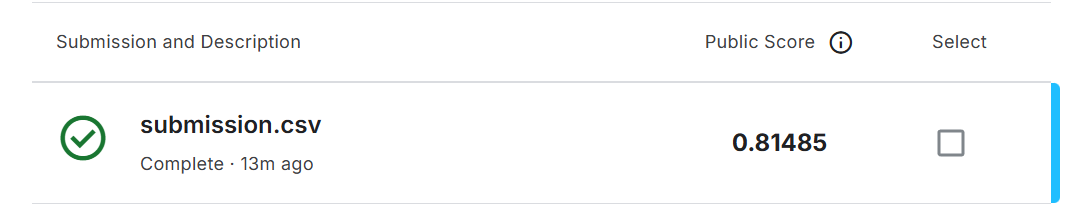